# 01 – Exploratory Data Analysis: MetroPT-3

Case study *Early Warning of Air-Leak Failures in Metro Compressors* (Group 6, MDM2, TH Deggendorf).

Contents:
1. Data overview
2. Data quality (missing values, duplicates, sampling, gaps, frozen segments)
3. Reported failures
4. Signal overview
5. Distributions and correlations
6. Signals around each failure
7. Compressor duty cycle
8. Train/test split
9. Summary
10. Threshold baseline

Data: Davari, N., Veloso, B., Ribeiro, R., & Gama, J. (2021). *MetroPT-3 Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5VW3R (CC BY 4.0). Run `python scripts/download_data.py` first. Figures are written to `results/figures/`.

In [ ]:
# Google Colab only: clone the repository and download the data
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    repo_dir = "/content/IntelligentSystemsCaseStudy"
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "https://github.com/mohamedfarez/IntelligentSystemsCaseStudy.git", repo_dir], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "scripts/download_data.py"], check=True)

In [2]:
import sys
from pathlib import Path

# Project root on the import path (works from the repository root or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT.resolve()))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from src import config
from src.data_loading import failure_mask, load_metropt3, quality_report

config.set_global_seed()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140, "display.max_columns", 30)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | scikit-learn {sklearn.__version__}")


def save(fig, name):
    """Save a figure to results/figures/ (PNG, 300 dpi)."""
    path = config.FIGURES_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved -> {path.relative_to(config.PROJECT_ROOT)}")


def shade_failures(ax, label=True):
    """Shade the reported failure periods on a time axis."""
    for i, p in config.FAILURE_PERIODS.iterrows():
        ax.axvspan(p["start"], p["end"], color="tab:red", alpha=0.25,
                   label="reported air leak" if (label and i == 0) else None)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | matplotlib 3.10.0 | seaborn 0.13.2 | scikit-learn 1.6.1


## 1. Data overview

In [3]:
raw_ts = pd.read_csv(config.RAW_CSV_PATH, usecols=lambda c: c.lower() == "timestamp")
raw_index = pd.DatetimeIndex(pd.to_datetime(raw_ts.iloc[:, 0]))
del raw_ts

df = load_metropt3()
print(f"Shape: {df.shape}  |  memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"Rows in raw file: {len(raw_index):,} (UCI states {config.EXPECTED_N_ROWS:,})")
df.head()

Shape: (1516948, 15)  |  memory: 103.2 MB
Rows in raw file: 1,516,948 (UCI states 1,516,948)


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_electric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.599998,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.674999,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.599998,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.424999,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.474998,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
TP2,1516948.0,1.368,3.258,-0.032,-0.014,-0.012,-0.010,10.676
TP3,1516948.0,8.985,0.639,0.730,8.492,8.960,9.492,10.302
H1,1516948.0,7.568,3.331,-0.036,8.254,8.784,9.374,10.288
DV_pressure,1516948.0,0.056,0.380,-0.032,-0.022,-0.020,-0.018,9.844
Reservoirs,1516948.0,8.985,0.638,0.712,8.494,8.960,9.492,10.300
Oil_temperature,1516948.0,62.644,6.515,15.400,57.775,62.700,67.250,89.050
Motor_current,1516948.0,2.050,2.302,0.020,0.040,0.045,3.807,9.295
COMP,1516948.0,0.837,0.371,0.000,1.000,1.000,1.000,1.000
DV_electric,1516948.0,0.161,0.369,0.000,0.000,0.000,0.000,1.000
Towers,1516948.0,0.920,0.273,0.000,1.000,1.000,1.000,1.000


## 2. Data quality

In [5]:
qr = quality_report(df, min_gap="5min", raw_index=raw_index)
print(qr.summary())

Rows:                     1,516,948
Period:                   2020-02-01 00:00:00 -> 2020-09-01 03:59:50
Duplicate timestamps:     0
Missing values (total):   0
Median sampling interval: 0 days 00:00:10
Gaps > threshold:         275 (total 37 days 18:10:33, 17.7 % of the period)
Frozen (flat-line) segs:  9 (total 7 days 01:56:08, 50,716 records)
Constant columns:         none
Non-binary digital cols:  none


In [6]:
print("Missing values per column:")
display(qr.missing_per_column.to_frame("n_missing").T)
print("Most frequent sampling intervals:")
display(qr.sampling_interval_counts.to_frame("count"))
print("Non-binary values in digital columns:", qr.digital_non_binary or "none")

Missing values per column:


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_electric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
n_missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Most frequent sampling intervals:


,count
timestamp,
0 days 00:00:10,1337521
0 days 00:00:09,128277
0 days 00:00:12,38321
0 days 00:00:13,7988
0 days 00:00:11,4471
0 days 00:00:21,10
0 days 00:00:19,5
0 days 00:00:22,4
0 days 00:05:08,3


Non-binary values in digital columns: none


In [7]:
print(f"{len(qr.gaps)} gaps longer than 5 min; the 15 longest:")
qr.gaps.head(15)

275 gaps longer than 5 min; the 15 longest:


,gap_start,gap_end,duration
0,2020-04-25 01:10:51,2020-04-27 01:12:49,2 days 00:01:58
1,2020-06-27 10:53:07,2020-06-28 23:07:43,1 days 12:14:36
2,2020-02-28 23:57:08,2020-03-01 04:00:09,1 days 04:03:01
3,2020-08-04 07:42:28,2020-08-05 08:23:01,1 days 00:40:33
4,2020-05-24 00:39:23,2020-05-25 01:14:14,1 days 00:34:51
5,2020-07-07 15:24:51,2020-07-08 15:20:51,0 days 23:56:00
6,2020-08-22 19:11:44,2020-08-23 18:51:01,0 days 23:39:17
7,2020-05-10 00:31:17,2020-05-10 22:48:58,0 days 22:17:41
8,2020-06-07 14:19:39,2020-06-08 11:48:04,0 days 21:28:25
9,2020-04-01 13:15:40,2020-04-02 09:59:17,0 days 20:43:37


saved -> results/figures/eda_01_records_per_day.png


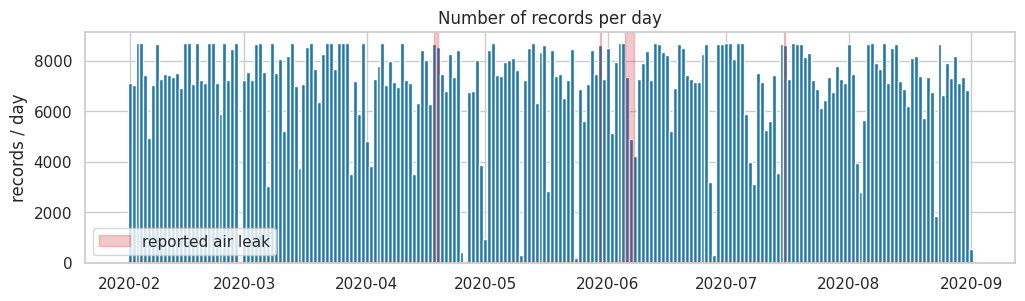

In [8]:
# Records per day
daily_counts = df["TP2"].resample("1D").count()
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(daily_counts.index, daily_counts.to_numpy(), width=1.0, color="tab:blue")
shade_failures(ax)
ax.set(title="Number of records per day", ylabel="records / day")
ax.legend(loc="lower left")
save(fig, "eda_01_records_per_day")
plt.show()

### Frozen segments

Periods of at least 30 minutes in which all analogue signals stay exactly constant. Pressures and oil temperature normally change within minutes, so these periods indicate a stalled data logger.

In [9]:
fl = qr.flatlines.copy()
fl["overlaps_failure_or_24h_before"] = [
    bool(((config.FAILURE_PERIODS["start"] - pd.Timedelta("24h") <= e) & (config.FAILURE_PERIODS["end"] >= s)).any())
    for s, e in zip(fl["start"], fl["end"])
]
print(f"{len(fl)} frozen segments, total {fl['duration'].sum()}, {fl['n_records'].sum():,} records "
      f"({100 * fl['n_records'].sum() / len(df):.2f} % of all records)")
fl

9 frozen segments, total 7 days 01:56:08, 50,716 records (3.34 % of all records)


,start,end,duration,n_records,overlaps_failure_or_24h_before
0,2020-04-13 18:29:10,2020-04-13 19:27:16,0 days 00:58:06,291,False
1,2020-04-17 09:20:33,2020-04-18 00:18:07,0 days 14:57:34,4470,True
2,2020-04-20 04:49:07,2020-04-21 01:16:52,0 days 20:27:45,6110,False
3,2020-05-26 09:19:26,2020-05-27 13:43:45,1 days 04:24:19,8466,False
4,2020-05-27 13:53:52,2020-05-28 03:16:28,0 days 13:22:36,3983,False
5,2020-06-12 02:01:46,2020-06-12 17:06:06,0 days 15:04:20,4502,False
6,2020-06-22 15:06:11,2020-06-25 05:08:35,2 days 14:02:24,18515,False
7,2020-07-21 13:45:02,2020-07-21 22:03:16,0 days 08:18:14,2481,False
8,2020-07-22 06:43:34,2020-07-22 13:04:24,0 days 06:20:50,1898,False


## 3. Reported failures

The data are unlabelled. The four air-leak failures listed on the UCI page are used as ground truth (`config.FAILURE_PERIODS`).

In [10]:
fp = config.FAILURE_PERIODS.copy()
fp["duration"] = fp["end"] - fp["start"]
is_fail = failure_mask(df.index)
fp["n_records"] = [int(((df.index >= s) & (df.index <= e)).sum()) for s, e in zip(fp["start"], fp["end"])]
print(f"Records inside failure periods: {is_fail.sum():,} ({100 * is_fail.mean():.2f} % of all records)")
fp

Records inside failure periods: 29,954 (1.97 % of all records)


,failure_id,start,end,failure_type,duration,n_records
0,1,2020-04-18 00:00:00,2020-04-18 23:59:00,Air leak,0 days 23:59:00,8657
1,2,2020-05-29 23:30:00,2020-05-30 06:00:00,Air leak,0 days 06:30:00,2360
2,3,2020-06-05 10:00:00,2020-06-07 14:30:00,Air leak,2 days 04:30:00,17315
3,4,2020-07-15 14:30:00,2020-07-15 19:00:00,Air leak,0 days 04:30:00,1622


## 4. Signal overview (10-minute means)

saved -> results/figures/eda_02_analog_overview.png


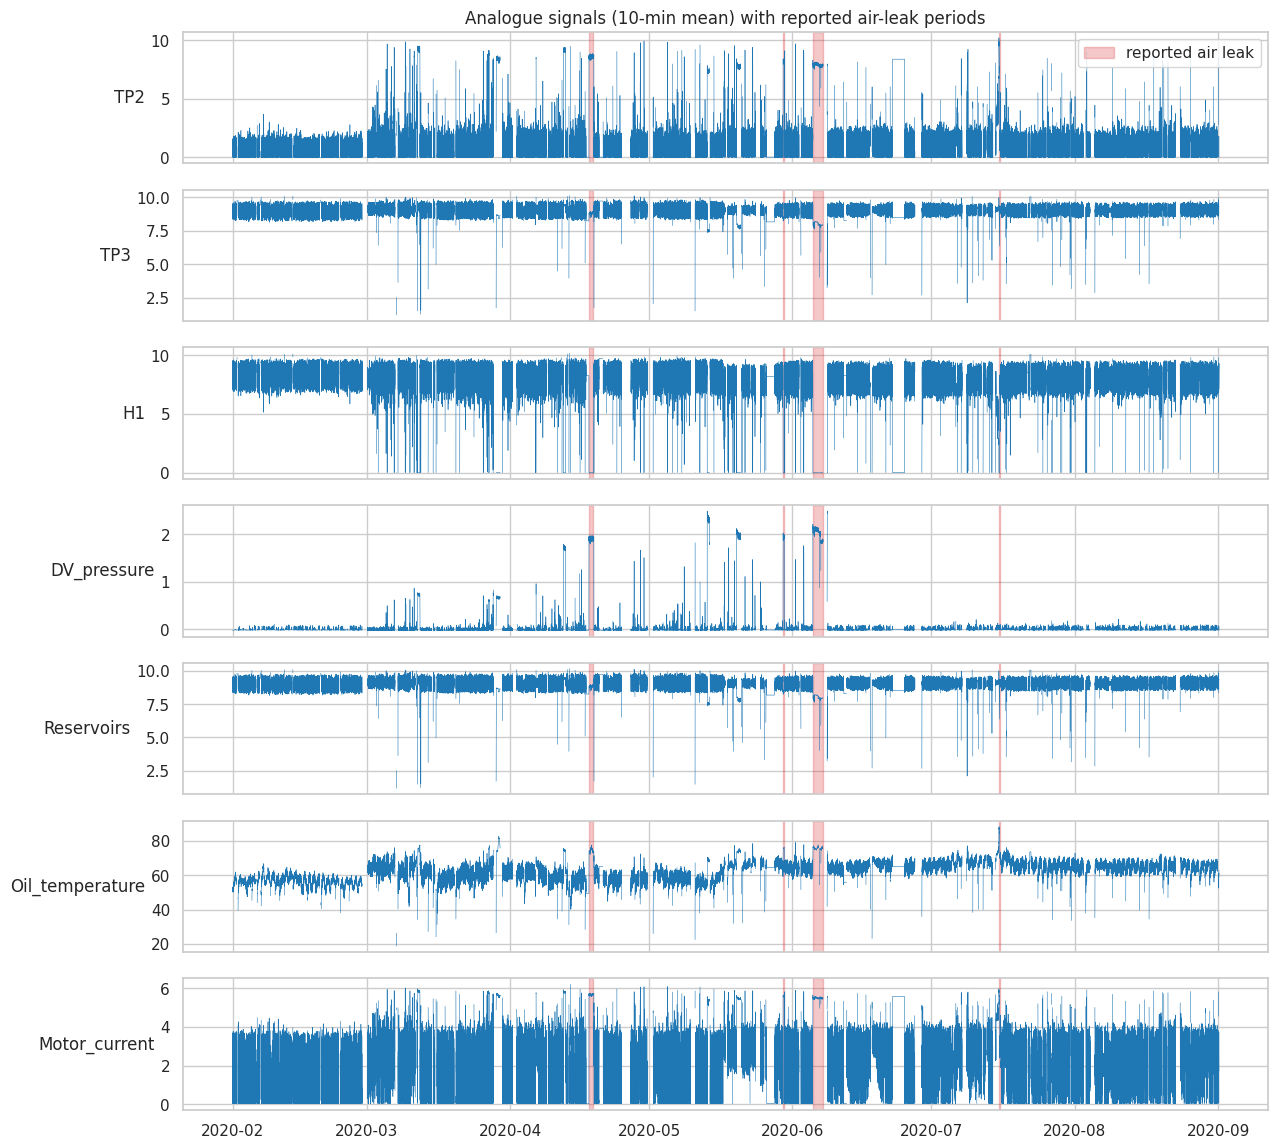

In [11]:
overview = df[config.ANALOG_COLS].resample("10min").mean()
fig, axes = plt.subplots(len(config.ANALOG_COLS), 1, figsize=(14, 2.0 * len(config.ANALOG_COLS)), sharex=True)
for ax, col in zip(axes, config.ANALOG_COLS):
    ax.plot(overview.index, overview[col], lw=0.4, color="tab:blue")
    shade_failures(ax, label=(col == config.ANALOG_COLS[0]))
    ax.set_ylabel(col, rotation=0, ha="right", va="center")
axes[0].legend(loc="upper right")
axes[0].set_title("Analogue signals (10-min mean) with reported air-leak periods")
save(fig, "eda_02_analog_overview")
plt.show()

saved -> results/figures/eda_03_digital_daily_activity.png


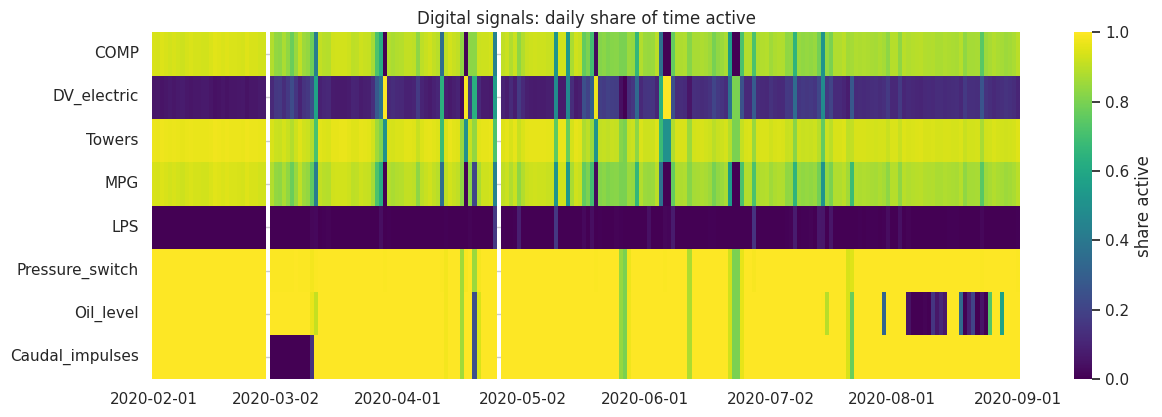

In [12]:
# Share of the day each digital signal is active
digital_daily = (df[config.DIGITAL_COLS] > 0.5).resample("1D").mean()
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(digital_daily.T, cmap="viridis", vmin=0, vmax=1, cbar_kws={"label": "share active"}, ax=ax,
            xticklabels=False)
ticks = np.linspace(0, len(digital_daily) - 1, 8).astype(int)
ax.set_xticks(ticks + 0.5)
ax.set_xticklabels([digital_daily.index[i].strftime("%Y-%m-%d") for i in ticks], rotation=0)
ax.set(title="Digital signals: daily share of time active", xlabel="")
save(fig, "eda_03_digital_daily_activity")
plt.show()

## 5. Distributions and correlations

saved -> results/figures/eda_04_analog_distributions.png


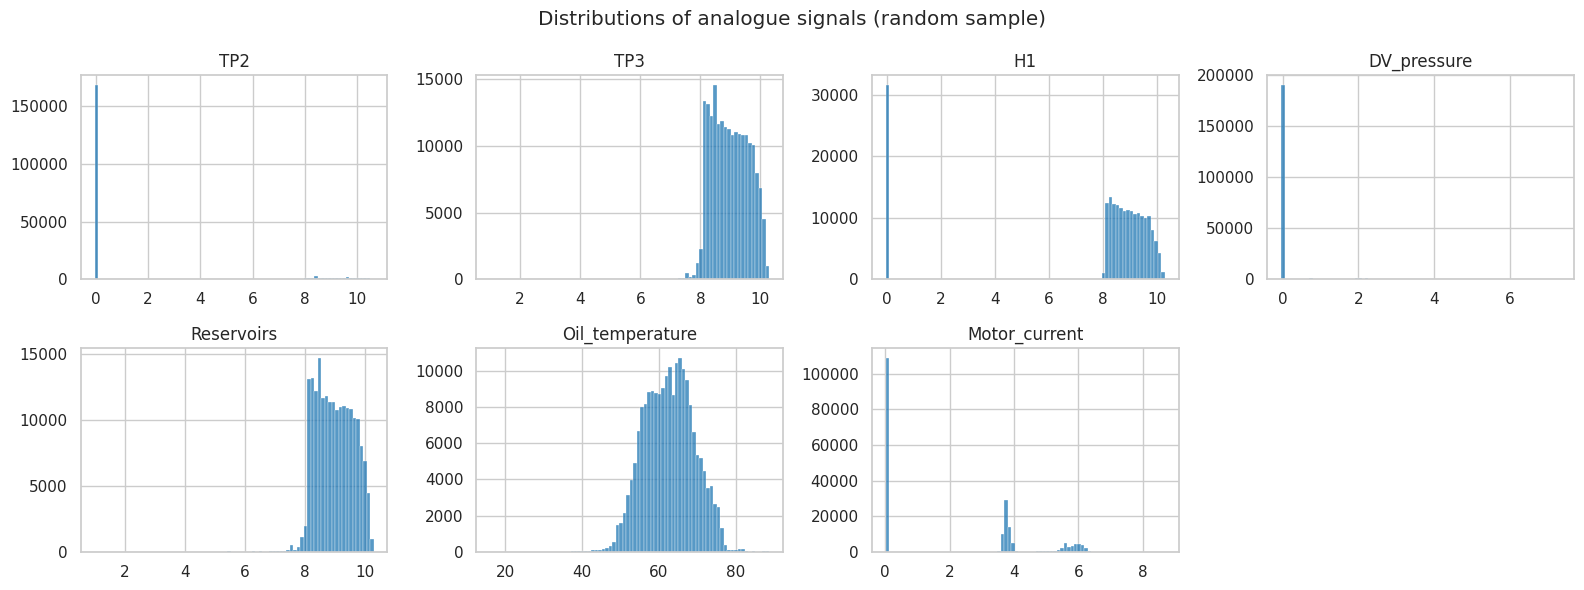

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), config.ANALOG_COLS):
    sample = df[col].sample(n=min(200_000, len(df)), random_state=config.RANDOM_SEED)
    sns.histplot(sample, bins=80, ax=ax, color="tab:blue")
    ax.set(title=col, xlabel="", ylabel="")
axes.ravel()[-1].axis("off")
fig.suptitle("Distributions of analogue signals (random sample)")
fig.tight_layout()
save(fig, "eda_04_analog_distributions")
plt.show()

saved -> results/figures/eda_05_motor_current_hist.png


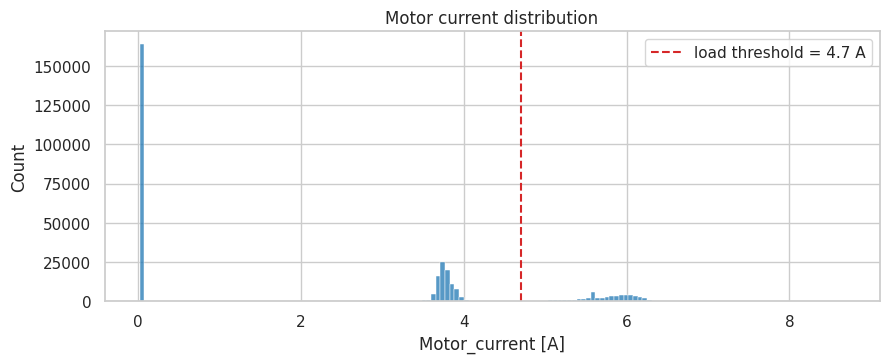

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.histplot(df["Motor_current"].sample(n=min(300_000, len(df)), random_state=config.RANDOM_SEED),
             bins=150, ax=ax, color="tab:blue")
ax.axvline(config.MOTOR_LOAD_CURRENT_A, color="tab:red", ls="--",
           label=f"load threshold = {config.MOTOR_LOAD_CURRENT_A} A")
ax.set(title="Motor current distribution", xlabel="Motor_current [A]")
ax.legend()
save(fig, "eda_05_motor_current_hist")
plt.show()

saved -> results/figures/eda_06_analog_correlation.png


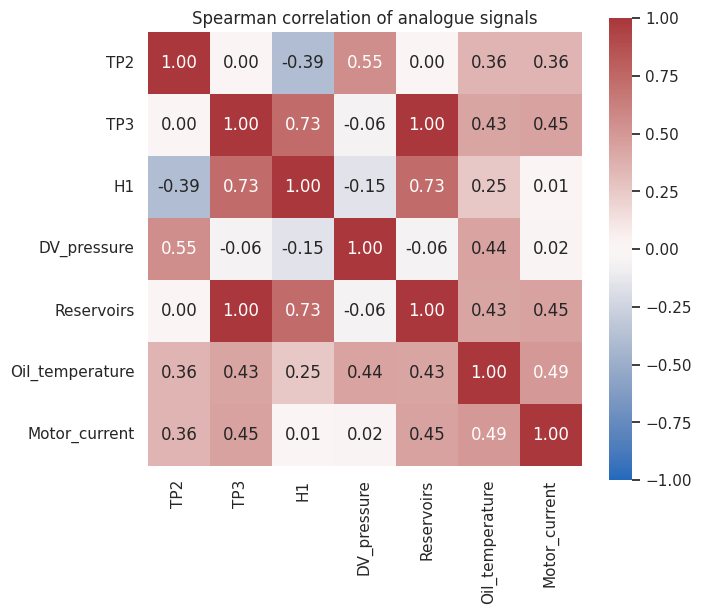

In [15]:
corr = df[config.ANALOG_COLS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation of analogue signals")
save(fig, "eda_06_analog_correlation")
plt.show()

## 6. Signals around each failure

48 h before to 12 h after each reported failure (1-minute means).

saved -> results/figures/eda_07_failure_1_zoom.png


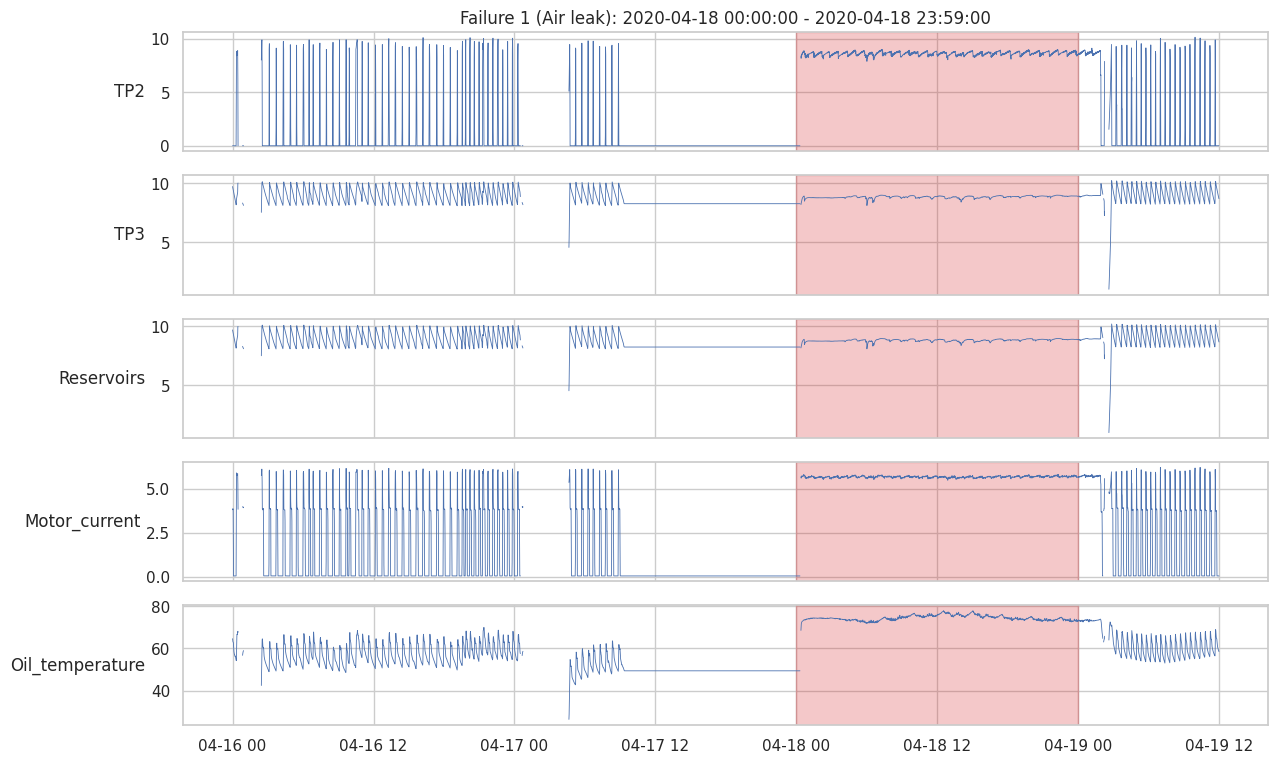

saved -> results/figures/eda_07_failure_2_zoom.png


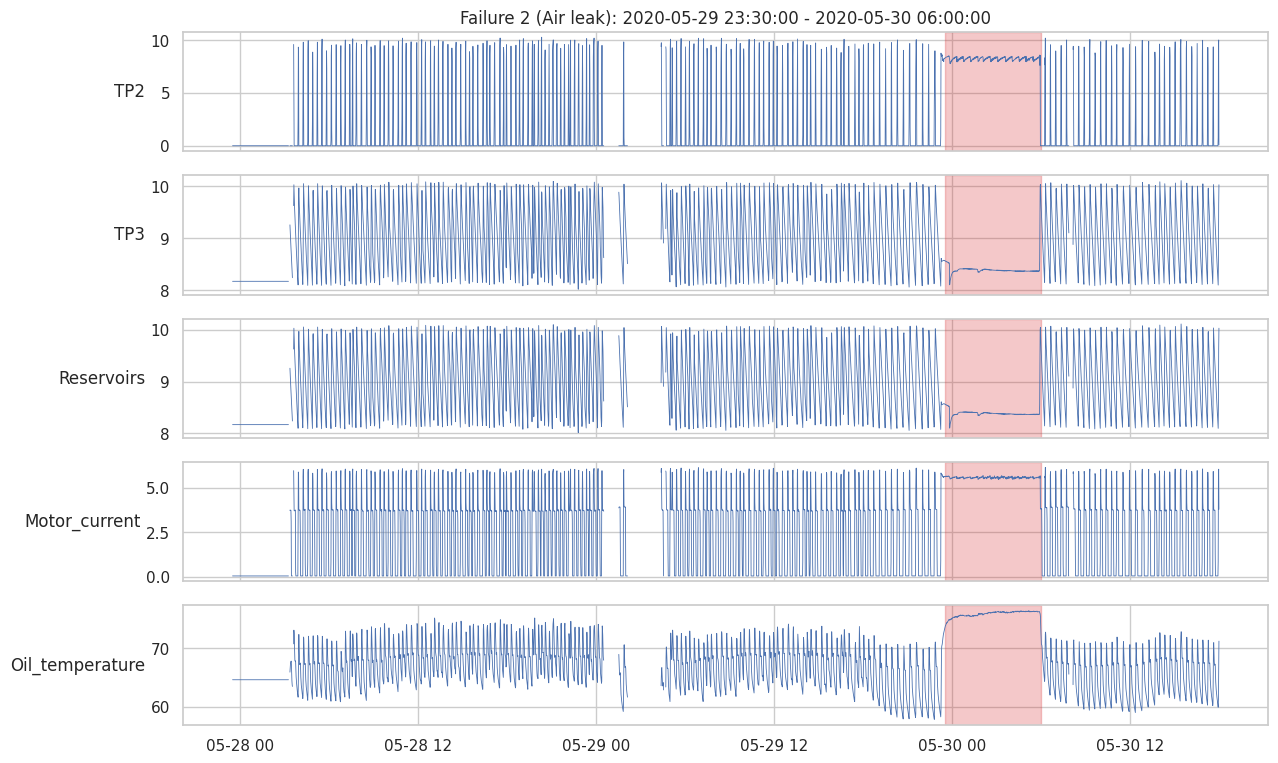

saved -> results/figures/eda_07_failure_3_zoom.png


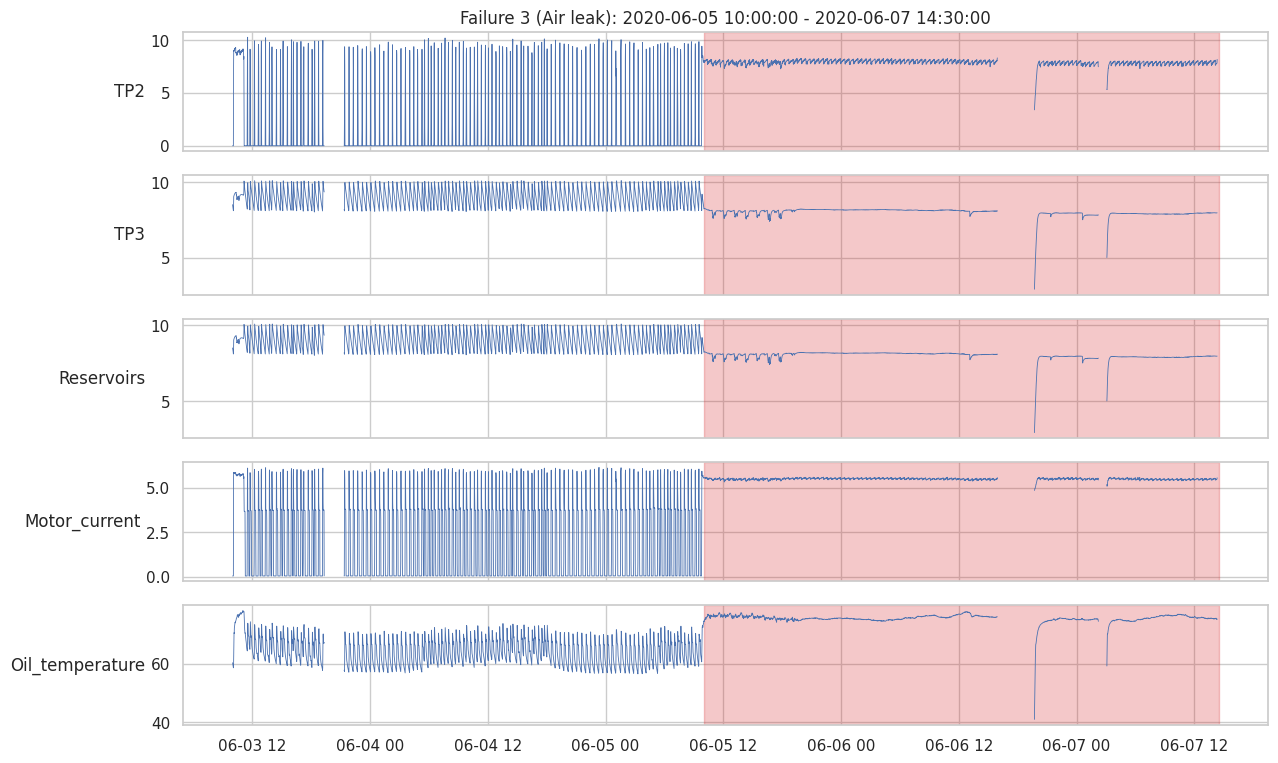

saved -> results/figures/eda_07_failure_4_zoom.png


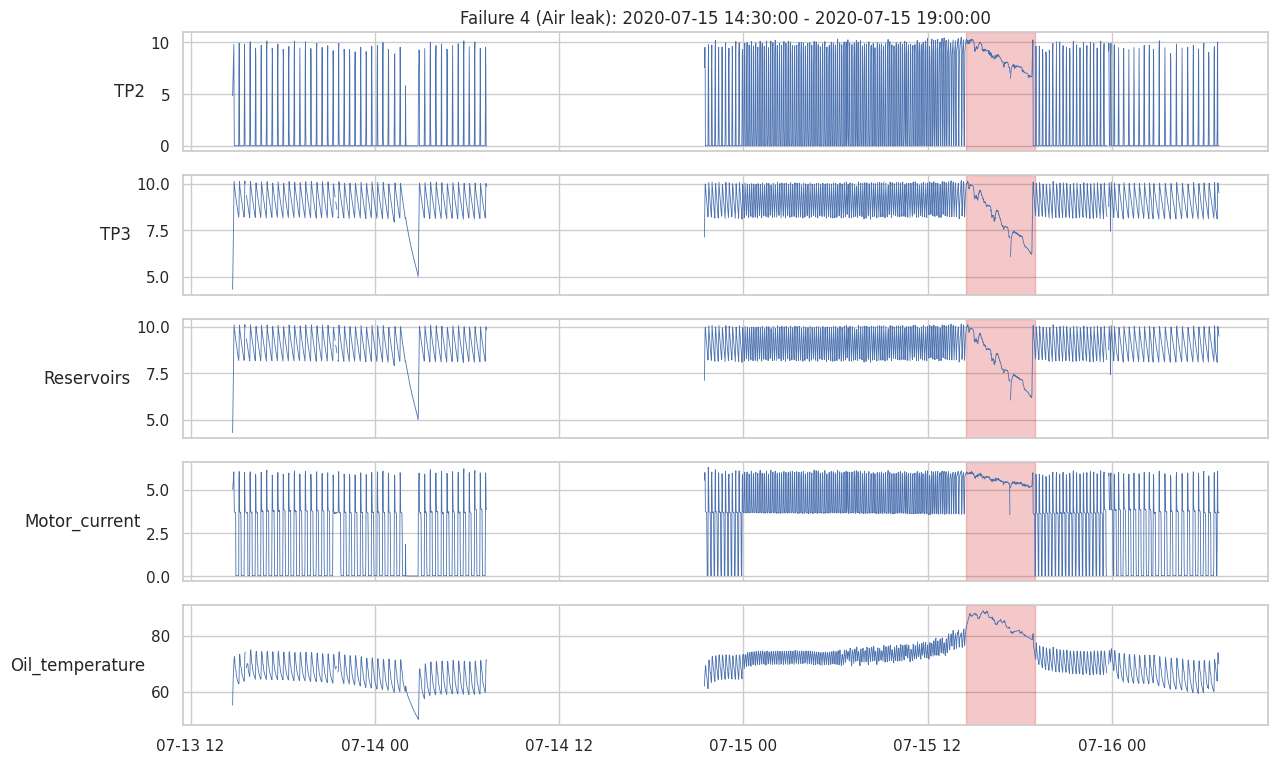

In [16]:
zoom_cols = ["TP2", "TP3", "Reservoirs", "Motor_current", "Oil_temperature"]
for _, p in config.FAILURE_PERIODS.iterrows():
    win = df.loc[p["start"] - pd.Timedelta("48h"): p["end"] + pd.Timedelta("12h"), zoom_cols]
    if win.empty:
        print(f"Failure {p['failure_id']}: no data in window")
        continue
    win = win.resample("1min").mean()
    fig, axes = plt.subplots(len(zoom_cols), 1, figsize=(14, 1.8 * len(zoom_cols)), sharex=True)
    for ax, col in zip(axes, zoom_cols):
        ax.plot(win.index, win[col], lw=0.6)
        ax.axvspan(p["start"], p["end"], color="tab:red", alpha=0.25)
        ax.set_ylabel(col, rotation=0, ha="right", va="center")
    axes[0].set_title(f"Failure {p['failure_id']} ({p['failure_type']}): {p['start']} - {p['end']}")
    save(fig, f"eda_07_failure_{p['failure_id']}_zoom")
    plt.show()

## 7. Compressor duty cycle

Share of each hour in which the motor current is above the load threshold (`load_ratio`). The same feature is used by the threshold baseline.

saved -> results/figures/eda_08_duty_cycle.png


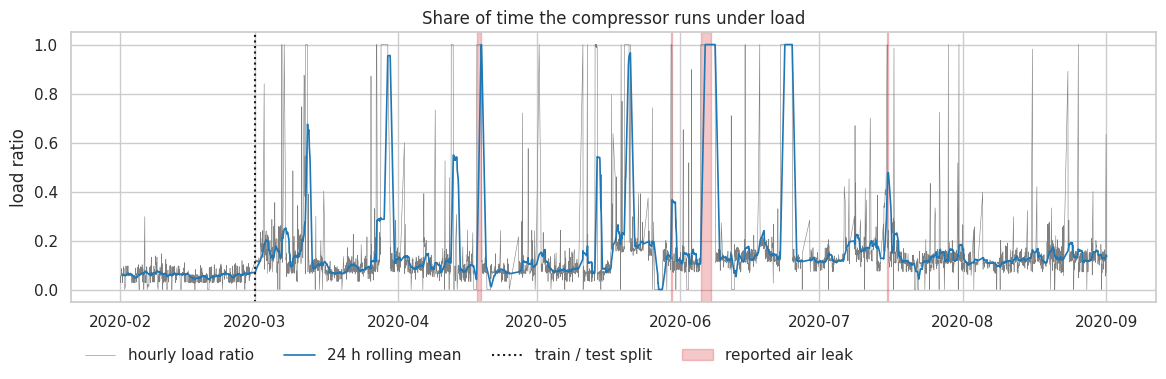

In [17]:
under_load = (df["Motor_current"] > config.MOTOR_LOAD_CURRENT_A).astype("float32")
duty = under_load.resample("1h").mean().dropna()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(duty.index, duty.to_numpy(), lw=0.4, color="tab:gray", label="hourly load ratio")
ax.plot(duty.index, duty.rolling(24, min_periods=12).mean(), lw=1.2, color="tab:blue", label="24 h rolling mean")
ax.axvline(config.TRAIN_END, color="k", ls=":", label="train / test split")
shade_failures(ax)
ax.set(title="Share of time the compressor runs under load", ylabel="load ratio")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=4, frameon=False)
save(fig, "eda_08_duty_cycle")
plt.show()

,count,mean,std,min,25%,50%,75%,max
phase,,,,,,,,
24 h before failure,86.0,0.161,0.167,0.00,0.072,0.118,0.160,0.857
failure,86.0,0.975,0.132,0.11,1.000,1.000,1.000,1.000
normal,4244.0,0.145,0.187,0.00,0.071,0.107,0.137,1.000


saved -> results/figures/eda_09_duty_cycle_by_phase.png


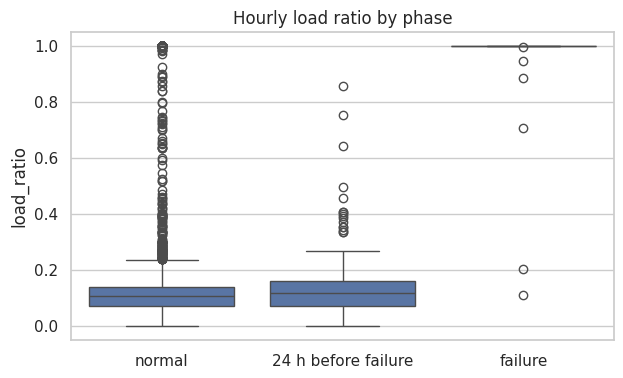

In [18]:
# Load ratio by phase
hourly = duty.to_frame("load_ratio")
hourly["phase"] = "normal"
for _, p in config.FAILURE_PERIODS.iterrows():
    hourly.loc[p["start"] - pd.Timedelta("24h"): p["start"], "phase"] = "24 h before failure"
    hourly.loc[p["start"]: p["end"], "phase"] = "failure"
display(hourly.groupby("phase")["load_ratio"].describe().round(3))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=hourly, x="phase", y="load_ratio", order=["normal", "24 h before failure", "failure"], ax=ax)
ax.set(title="Hourly load ratio by phase", xlabel="")
save(fig, "eda_09_duty_cycle_by_phase")
plt.show()

## 8. Train/test split

In [19]:
train_mask = df.index < config.TRAIN_END
split = pd.DataFrame({
    "period": ["train", "test"],
    "start": [df.index[train_mask].min(), df.index[~train_mask].min()],
    "end": [df.index[train_mask].max(), df.index[~train_mask].max()],
    "n_records": [int(train_mask.sum()), int((~train_mask).sum())],
    "n_failure_records": [int(is_fail[train_mask].sum()), int(is_fail[~train_mask].sum())],
})
split

,period,start,end,n_records,n_failure_records
0,train,2020-02-01 00:00:00,2020-02-28 23:57:08,214850,0
1,test,2020-03-01 04:00:09,2020-09-01 03:59:50,1302098,29954


## 9. Summary

Data quality
- 1,516,948 records, no missing values, no duplicate timestamps.
- Median sampling interval 10 s.
- 275 gaps longer than 5 min (37.8 days, 17.7 % of the period); 29 February is missing.
- 9 frozen segments (7 days 2 h, 3.3 % of records), including 17 April 09:20 to 18 April 00:18, directly before failure 1, and 22–25 June. These records need to be masked.
- `Caudal_impulses` is inactive in early March and `Oil_level` repeatedly in August.

Signals
- `Motor_current` has three states: about 0 A (off), 3.8 A (offloaded) and 5.4–6.3 A (loaded). The load threshold is set to 4.7 A.
- `TP3` and `Reservoirs` are almost identical.
- February (training month) shows a lower duty cycle and oil temperature and no `H1` drops, i.e. a distribution shift towards the test period.

Failures
- Hourly load ratio: 0.975 during failures, 0.161 in the 24 h before, 0.145 in normal operation. Leaks are clearly visible once they occur but hardly announced in advance.
- Sustained high-load periods also occur outside the reported failures (March, mid-April, around 20 May). The full-load period on 22–25 June is a frozen segment.
- `DV_pressure` shows repeated spikes from April to early June, which stop after the maintenance on 8 June.

## 10. Threshold baseline

Same data and split as above; equivalent to `python -m src.threshold_baseline`.

In [20]:
from dataclasses import asdict
from src.threshold_baseline import BaselineConfig, run_baseline

bl_cfg = BaselineConfig()
bl = run_baseline(df, bl_cfg)
print("Config:", asdict(bl_cfg))
print("Thresholds (fitted on training period):", {k: round(v, 3) for k, v in bl["model"].thresholds_.items()})
display(bl["events"])
display(pd.Series(bl["summary"], name="value").to_frame())

config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
bl["events"].to_csv(config.RESULTS_DIR / "baseline_threshold_events.csv", index=False)
pd.Series(bl["summary"]).to_csv(config.RESULTS_DIR / "baseline_threshold_summary.csv", header=["value"])

Config: {'window': '10min', 'low_quantile': 0.01, 'high_quantile': 0.99, 'min_rules': 2, 'persistence': 3, 'warning_horizon': '2h', 'load_current_a': 4.7}
Thresholds (fitted on training period): {'tp3_min': 7.903, 'reservoirs_min': 7.906, 'load_ratio': 0.233, 'motor_current_mean': 3.89}


,failure_id,start,end,detected,first_alarm,lead_time_min,early_warning
0,1,2020-04-18 00:00:00,2020-04-18 23:59:00,True,2020-04-18 00:50:00,-50.0,False
1,2,2020-05-29 23:30:00,2020-05-30 06:00:00,True,2020-05-29 23:50:00,-20.0,False
2,3,2020-06-05 10:00:00,2020-06-07 14:30:00,True,2020-06-05 10:20:00,-20.0,False
3,4,2020-07-15 14:30:00,2020-07-15 19:00:00,True,2020-07-15 12:30:00,120.0,True


,value
n_failures,4.000000
n_detected,4.000000
n_early_warnings,1.000000
event_recall,1.000000
median_lead_time_min,-20.000000
n_alarm_episodes,51.000000
n_false_alarm_episodes,45.000000
false_alarms_per_day,0.244574
window_precision,0.323834
window_recall,0.910747


saved -> results/figures/baseline_01_alarms_test_period.png


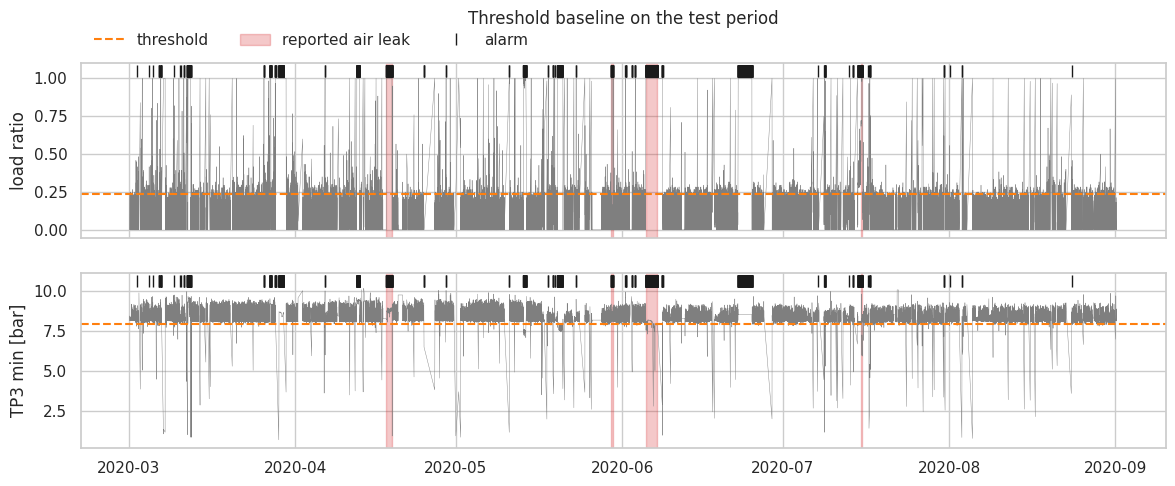

In [21]:
# Alarms in the test period
feats_test = bl["features"].loc[bl["alarms"].index]
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axes[0].plot(feats_test.index, feats_test["load_ratio"], lw=0.3, color="tab:gray")
axes[0].axhline(bl["model"].thresholds_["load_ratio"], color="tab:orange", ls="--", label="threshold")
axes[0].set(ylabel="load ratio")
axes[1].plot(feats_test.index, feats_test["tp3_min"], lw=0.3, color="tab:gray")
axes[1].axhline(bl["model"].thresholds_["tp3_min"], color="tab:orange", ls="--")
axes[1].set(ylabel="TP3 min [bar]")
alarm_t = bl["alarms"].index[bl["alarms"].to_numpy()]
for ax in axes:
    shade_failures(ax, label=(ax is axes[0]))
    ax.plot(alarm_t, np.full(len(alarm_t), ax.get_ylim()[1]), "|", color="k", ms=8,
            label="alarm" if ax is axes[0] else None)
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.25), ncol=3, frameon=False)
axes[0].set_title("Threshold baseline on the test period", pad=28)
save(fig, "baseline_01_alarms_test_period")
plt.show()

### Result

- All four failures are detected, but only failure 4 before its reported start (+120 min). Failures 1–3 are detected 50, 20 and 20 min after the start; before failure 1 the logger was frozen.
- 45 false-alarm episodes in the test period (about 0.24 per day); window-level precision 0.32, recall 0.91, F1 0.48.
- The longest false-alarm block (22–25 June) lies in a frozen segment.

The baseline detects ongoing leaks but gives almost no early warning.